# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 3 - Module 3
### **Practical 10: Complete Genetic Algorithm Optimization System using DEAP**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module III: Genetic Algorithms and Evolutionary Computing |
| **Student Name** | *Yashvi Shivhare* |
| **Enrollment No.** | *2023BTCSE021* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To design and implement a complete optimization system using a Genetic Algorithm in Python with the DEAP library by integrating population initialization, fitness evaluation, selection, crossover, mutation, and convergence analysis.

### 2. Theory: Modular Evolutionary Design with DEAP

DEAP separates representation (`creator`), genetic operators (`base.Toolbox`), and evolutionary loops (`algorithms.eaSimple`), making it easy to log per-generation statistics and track the best individual via `HallOfFame`.

### 3. Step 1: Running DEAP GA on 35-Bit OneMax

Best Individual: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Best Fitness:    35.0


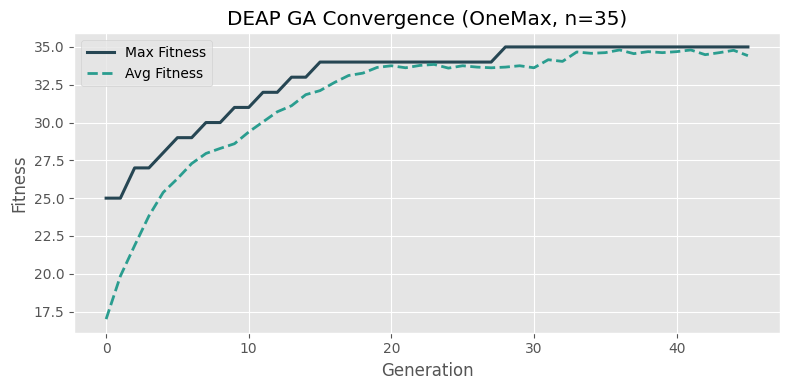

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from deap import base, creator, tools, algorithms

random.seed(1010)
np.random.seed(1010)
plt.style.use('ggplot')

if not hasattr(creator, "FitnessMax"):
    creator.create("FitnessMax", base.Fitness, weights=(1.0,))
if not hasattr(creator, "Individual"):
    creator.create("Individual", list, fitness=creator.FitnessMax)

toolbox = base.Toolbox()
toolbox.register("attr_bool", random.randint, 0, 1)
toolbox.register("individual", tools.initRepeat, creator.Individual, toolbox.attr_bool, n=35)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)
toolbox.register("evaluate", lambda ind: (sum(ind),))
toolbox.register("mate", tools.cxTwoPoint)
toolbox.register("mutate", tools.mutFlipBit, indpb=0.05)
toolbox.register("select", tools.selTournament, tournsize=3)

pop = toolbox.population(n=45)
hof = tools.HallOfFame(1)
stats = tools.Statistics(lambda ind: ind.fitness.values[0])
stats.register("avg", np.mean)
stats.register("max", np.max)

pop, log = algorithms.eaSimple(pop, toolbox, cxpb=0.75, mutpb=0.2, ngen=45, stats=stats, halloffame=hof, verbose=False)

print("Best Individual:", hof[0])
print("Best Fitness:   ", hof[0].fitness.values[0])

gens = log.select("gen")
plt.figure(figsize=(8, 4))
plt.plot(gens, log.select("max"), label="Max Fitness", color="#264653", linewidth=2.2)
plt.plot(gens, log.select("avg"), label="Avg Fitness", color="#2a9d8f", linewidth=2, linestyle="--")
plt.title("DEAP GA Convergence (OneMax, n=35)")
plt.xlabel("Generation")
plt.ylabel("Fitness")
plt.legend()
plt.tight_layout()
plt.show()

### 4. Conclusion
A complete GA optimization pipeline was built using DEAP, achieving optimal fitness on the 35-bit OneMax problem.